# Jour 4 — Diagnostic stratégique Superstore

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1705/chapter/4339), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Préparation
Les lignes sont des articles de commandes ; Order ID peut donc se répéter légitimement. Suppression des doublons exacts seulement. Les dates sont converties et les codes postaux restent des identifiants. Les marges agrégées sont somme(Profit)/somme(Sales), sans moyenne non pondérée des marges de lignes.

In [2]:
df = pd.read_excel(course_file("Datasets-DA-Bootcamp-2-", "Week 5 - Data Processing/W5D5 - Mini-project - bis/US Superstore data.xls"))
print("Avant nettoyage", df.shape, "doublons", df.duplicated().sum())
display(df.isna().sum().to_frame("manquants"))
df = df.drop_duplicates().copy()
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
# Les codes postaux sont des identifiants ; une absence ne signifie pas zéro.
df["Postal Code"] = df["Postal Code"].astype("Int64").astype("string").str.zfill(5)
assert df[["Sales", "Profit", "Order Date"]].notna().all().all()
df["Profit Margin"] = df["Profit"].div(df["Sales"].replace(0,np.nan))*100
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month"] = df["Order Date"].dt.to_period("M")
print("Après nettoyage",df.shape)
display(df.head())

Avant nettoyage (9994, 21) doublons 0


/var/folders/tn/21t5tzkd48z82_wfylsc12l00000gn/T/ipykernel_55759/4250579115.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(course_file("Datasets-DA-Bootcamp-2-", "Week 5 - Data Processing/W5D5 - Mini-project - bis/US Superstore data.xls"))


,manquants
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Après nettoyage (9994, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin,Order Year,Order Month,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,2016,11,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,2016,11,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,2016,6,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,2015,10,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,2015,10,2015-10


## Questions de décision
Où les ventes se concentrent-elles ? Quels produits génèrent le plus de profit ? Les remises élevées sont-elles associées à des pertes ? L’objectif est d’orienter les audits et les tests commerciaux.

## Courbe mensuelle interactive

interactive(children=(Dropdown(description='Category', options=('All', 'Furniture', 'Office Supplies', 'Techno…

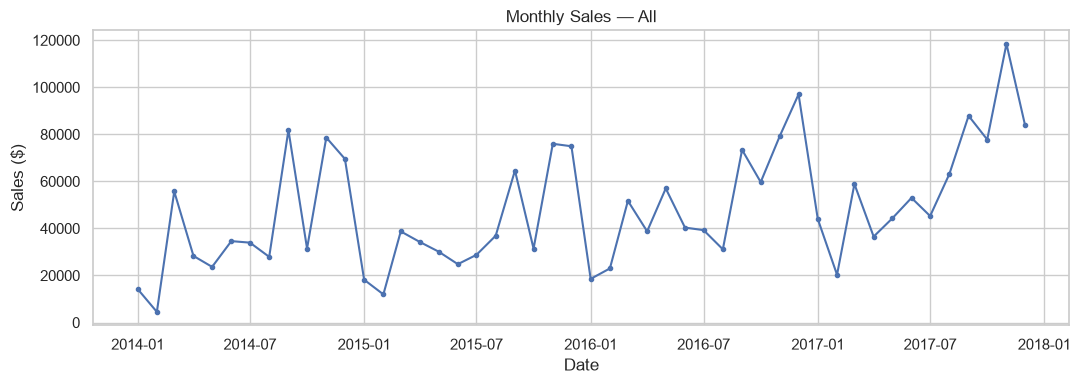

In [3]:
import ipywidgets as widgets
from ipywidgets import interact

def plot_monthly(category="All"):
    subset=df if category=="All" else df.loc[df["Category"].eq(category)]
    monthly=subset.groupby("Month")["Sales"].sum()
    plt.figure(figsize=(11,4));plt.plot(monthly.index.to_timestamp(),monthly.values,marker=".")
    plt.title(f"Monthly Sales — {category}");plt.xlabel("Date");plt.ylabel("Sales ($)");plt.tight_layout();plt.show()
interact(plot_monthly,category=widgets.Dropdown(options=["All"]+sorted(df["Category"].unique()),description="Category"));
# Vue statique disponible dans GitHub même sans noyau interactif.
plot_monthly("All")


## Répartition géographique avec Top N

interactive(children=(IntSlider(value=10, description='Top N', max=49, min=5), Output()), _dom_classes=('widge…

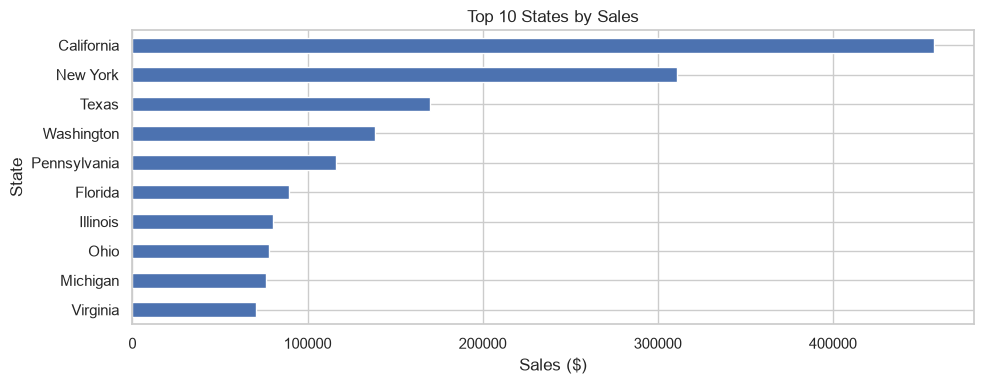

In [4]:
states=df.groupby("State")["Sales"].sum().sort_values()
def plot_states(top_n=10):
    states.tail(top_n).plot.barh(figsize=(10,max(4,top_n*.25)),title=f"Top {top_n} States by Sales")
    plt.xlabel("Sales ($)");plt.tight_layout();plt.show()
interact(plot_states,top_n=widgets.IntSlider(min=5,max=len(states),value=10,description="Top N"));
plot_states(10)

## Produits les plus rentables

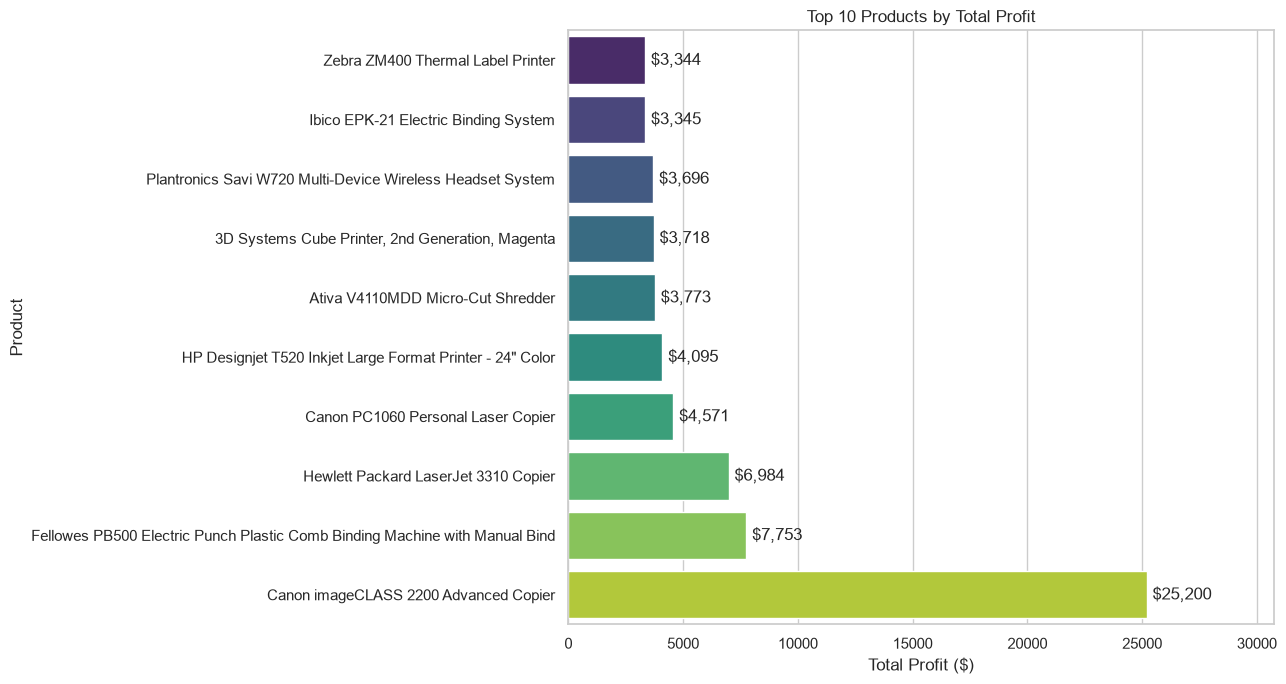

In [5]:
products=df.groupby("Product Name")["Profit"].sum().nlargest(10).sort_values()
fig,ax=plt.subplots(figsize=(13,7))
sns.barplot(x=products.values,y=products.index,hue=products.index,palette="viridis",legend=False,ax=ax)
ax.bar_label(ax.containers[0],fmt="%.0f",padding=3) if len(ax.containers)==1 else None
# Annotations explicites pour toutes les barres malgré plusieurs groupes de couleurs.
for i,value in enumerate(products.values):ax.text(value+products.max()*.01,i,f"${value:,.0f}",va="center")
ax.set(xlabel="Total Profit ($)",ylabel="Product",title="Top 10 Products by Total Profit");ax.set_xlim(0,products.max()*1.22)
plt.tight_layout();plt.show()

## Remises et profit
Les relations sont descriptives : catégories, coûts et clients peuvent expliquer une partie de l’association. On examine les niveaux de remise dans chaque catégorie avant de proposer un seuil à tester.

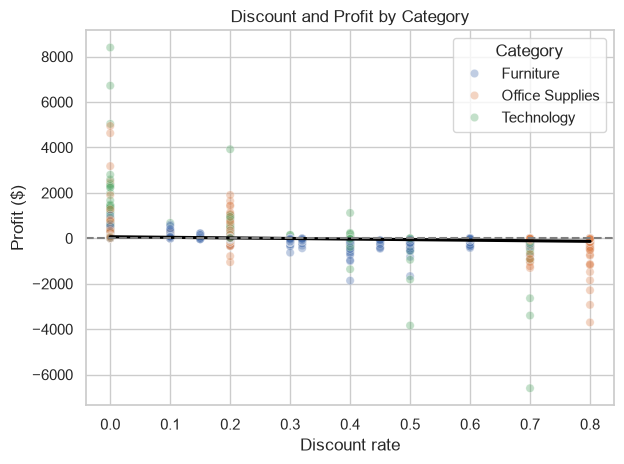

count        mean        total  loss_rate
Category        Discount                                           
Furniture       0.00        836   69.537173   58133.0764   0.000000
                0.10         76   93.565946    7111.0119   0.052632
                0.15         52   27.288298    1418.9915   0.326923
                0.20        615   10.188535    6265.9491   0.269919
                0.30        222  -48.177103  -10695.3169   0.932432
                0.32         27  -88.560656   -2391.1377   1.000000
                0.40         75 -215.831957  -16187.3968   1.000000
                0.45         11 -226.646464   -2493.1111   1.000000
                0.50         54 -238.355537  -12871.1990   1.000000
                0.60        138  -43.077212   -5944.6552   1.000000
                0.70         15 -259.662627   -3894.9394   1.000000
Office Supplies 0.00       3129   41.708567  130506.1064   0.000000
                0.10         16   67.880050    1086.0808   0.000000
                0.20       2201   17.282486   38038.7512   0.093594
                0.70        380  -43.687101  -16601.0984   1.000000
                0.80        300 -101.796797  -30539.0392   1.000000
Technology      0.00        833  158.881657  132348.4204   0.000000
                0.10          2  416.042150     832.0843   0.000000
                0.20        841   54.735560   46032.6057   0.154578
                0.30          5   65.207900     326.0395   0.200000
                0.40        131  -52.440104   -6869.6536   0.801527
                0.50         12 -636.269092   -7635.2291   1.000000
                0.70         23 -851.274743  -19579.3191   1.000000

Remises >20 % :


,count,mean,loss_rate
Category,,,
Furniture,542,-100.512465,0.972325
Office Supplies,680,-69.323732,1.000000
Technology,171,-197.416154,0.824561


In [6]:
sns.scatterplot(data=df,x="Discount",y="Profit",hue="Category",alpha=.35)
sns.regplot(data=df,x="Discount",y="Profit",scatter=False,color="black",ci=None)
plt.axhline(0,color="grey",ls="--");plt.title("Discount and Profit by Category");plt.xlabel("Discount rate");plt.ylabel("Profit ($)");plt.tight_layout();plt.show()
report=df.groupby(["Category","Discount"])["Profit"].agg(count="size",mean="mean",total="sum",loss_rate=lambda x:(x<0).mean())
display(report)
print("Remises >20 % :")
display(df.loc[df["Discount"]>.2].groupby("Category")["Profit"].agg(count="size",mean="mean",loss_rate=lambda x:(x<0).mean()))

## Matplotlib et Seaborn
Matplotlib offre un contrôle précis des axes, annotations et mises en page ; il convient aux courbes temporelles et au pilotage par widgets. Seaborn facilite les regroupements visuels, palettes, légendes et graphiques statistiques sur DataFrame. Les deux fonctionnent avec ipywidgets. Ici, la courbe montre la variation temporelle et le nuage révèle l’hétérogénéité par catégorie. Aucun des deux ne rend l’analyse interactive sur la prévisualisation statique GitHub : ouvrir le notebook dans Jupyter ou Colab.

## Synthèse pour décision

In [7]:
sales=df["Sales"].sum();profit=df["Profit"].sum()
top=df.groupby("State")["Sales"].sum().sort_values(ascending=False)
high=df.loc[df["Discount"]>.2]
display(Markdown(f"- Ventes : **${sales:,.0f}** ; profit : **${profit:,.0f}**, marge pondérée : **{profit/sales:.1%}**.\n- Premier État : **{top.index[0]}** ; les cinq premiers représentent **{top.head(5).sum()/sales:.1%}** des ventes. Prioriser des tests dans les marchés rentables.\n- Produit le plus rentable : **{products.idxmax()}** ; vérifier stock et coûts d’acquisition.\n- Parmi {len(high)} lignes à remise >20 %, **{(high['Profit']<0).mean():.1%}** sont déficitaires. Auditer les remises et tester des plafonds par catégorie avec suivi du profit incrémental."))

- Ventes : **$2,297,201** ; profit : **$286,397**, marge pondérée : **12.5%**.
- Premier État : **California** ; les cinq premiers représentent **52.0%** des ventes. Prioriser des tests dans les marchés rentables.
- Produit le plus rentable : **Canon imageCLASS 2200 Advanced Copier** ; vérifier stock et coûts d’acquisition.
- Parmi 1393 lignes à remise >20 %, **96.8%** sont déficitaires. Auditer les remises et tester des plafonds par catégorie avec suivi du profit incrémental.